# 01 · Explore the data and check for leakage

Builds the label and the day-28 feature table, then checks that nothing dated after day 28 got in.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

In [2]:
from src.features import *
students, vle, sub, top_types = load_all()
students.attrs['exclusions']

{'all_rows': 32593,
 'unregistered_by_cutoff': 5055,
 'registered_after_cutoff': 16,
 'kept': 27522}

## The label

At risk = Withdrawn or Fail. Students who unregistered on or before day 28 (or had not registered yet) are excluded.

In [3]:
pd.crosstab(students['code_presentation'], students['final_result'], margins=True)

final_result,Distinction,Fail,Pass,Withdrawn,All
code_presentation,,,,,
2013B,327,1240,1766,789,4122
2013J,748,1992,3725,1215,7680
2014B,784,1830,2573,1322,6509
2014J,1164,1975,4292,1780,9211
All,3023,7037,12356,5106,27522


In [4]:
students.groupby(['year'])['at_risk'].agg(['size', 'mean']).round(3)

,size,mean
year,,
2013,11802,0.444
2014,15720,0.439


In [5]:
students.groupby('code_module')['at_risk'].agg(['size', 'mean']).round(3)

,size,mean
code_module,,
AAA,717,0.259
BBB,6429,0.417
CCC,3517,0.523
DDD,5279,0.506
EEE,2552,0.353
FFF,6591,0.447
GGG,2437,0.379


## Day-28 features

In [6]:
X = build_features(students, vle, sub, top_types)
print(X.shape)
print('activity types used:', top_types)
X.describe().T.round(1)

(27522, 25)
activity types used: ['forumng', 'homepage', 'oucontent', 'subpage', 'quiz', 'resource']


,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,27522.0,0.2,0.5,0.0,0.0,0.0,0.0,6.0
studied_credits,27522.0,76.3,38.2,30.0,60.0,60.0,90.0,630.0
date_registration,27515.0,-66.5,47.5,-311.0,-95.0,-53.0,-29.0,28.0
total_clicks,27522.0,357.0,430.9,0.0,90.0,225.0,470.0,7697.0
clicks_pre,27522.0,74.8,136.4,0.0,3.0,27.0,88.0,3731.0
clicks_w1,27522.0,70.8,110.6,0.0,5.0,34.0,93.0,4385.0
clicks_w2,27522.0,63.6,94.5,0.0,4.0,30.0,84.0,1566.0
clicks_w3,27522.0,82.0,107.6,0.0,8.0,45.0,117.0,1709.0
clicks_w4,27522.0,65.7,102.6,0.0,3.0,28.0,86.0,2346.0
active_days,27522.0,14.7,10.4,0.0,7.0,13.0,21.0,54.0


## How early activity differs by outcome

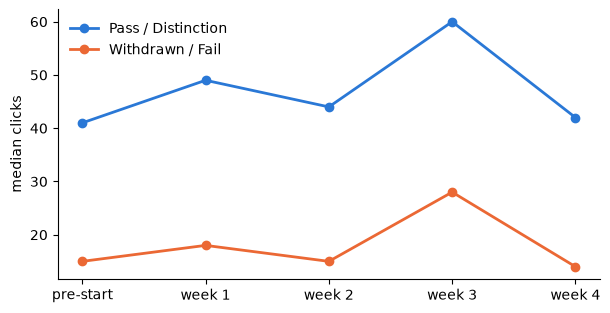

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
y = students.set_index('sid')['at_risk']
weeks = ['clicks_pre', 'clicks_w1', 'clicks_w2', 'clicks_w3', 'clicks_w4']
for label, color, name in [(0, '#2a78d6', 'Pass / Distinction'), (1, '#eb6834', 'Withdrawn / Fail')]:
    ax.plot(range(5), X.loc[y == label, weeks].median(), color=color, lw=2, marker='o', label=name)
ax.set_xticks(range(5), ['pre-start', 'week 1', 'week 2', 'week 3', 'week 4'])
ax.set_ylabel('median clicks')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)

Share of students with **no** logged activity by day 28 - this is the group that a logging failure would make everyone look like:

In [8]:
(X['total_clicks'] == 0).groupby(y).mean().rename({0: 'not at risk', 1: 'at risk'}).round(3)

at_risk
not at risk    0.010
at risk        0.062
Name: total_clicks, dtype: float64

## Leakage checks

In [9]:
info_cols = pd.read_csv(DATA_DIR / 'studentInfo.csv', nrows=1).columns
assert vle['date'].max() <= CUTOFF, 'activity after day 28'
assert sub['date_submitted'].max() <= CUTOFF, 'assessment submitted after day 28'
assessment_types = pd.read_csv(DATA_DIR / 'assessments.csv').set_index('id_assessment')['assessment_type']
assert (assessment_types.loc[sub['id_assessment']] != 'Exam').all(), 'exam used'
forbidden = {'date_unregistration', 'final_result', 'at_risk', 'gender', 'code_module', 'code_presentation'}
assert not forbidden & set(X.columns), forbidden & set(X.columns)
print('max VLE date:', vle['date'].max(), '| max submission date:', sub['date_submitted'].max())
print('all leakage checks passed')

max VLE date: 28 | max submission date: 28
all leakage checks passed


The leaky comparison (whole-course activity instead of day 28) is computed by `src.experiments.leaky_demo` and saved to `results/leaky_demo.txt`:

In [10]:
print((Path.cwd().parent / 'results' / 'leaky_demo.txt').read_text())

HGB AUC with whole-course activity (leaky): 0.949

